In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
pred = pd.read_csv(
    "../data/processed/xgboost_predictions.csv",
    parse_dates=["Date"]
)

pred.head()

,Date,Store,Sales,XGBoost_Prediction
0,2015-02-06,1,5022,4994.4490
1,2015-02-06,2,5260,5534.5107
2,2015-02-06,3,7920,7222.4210
3,2015-02-06,4,10985,10423.4840
4,2015-02-06,5,5209,5191.5444


In [3]:
print("Rows:", len(pred))
print("Stores:", pred["Store"].nunique())
print("Date range:", pred["Date"].min(), "to", pred["Date"].max())
print("Missing values:\n", pred.isnull().sum())

Rows: 162796
Stores: 1115
Date range: 2015-02-06 00:00:00 to 2015-07-31 00:00:00
Missing values:
 Date                  0
Store                 0
Sales                 0
XGBoost_Prediction    0
dtype: int64


In [4]:
pred["Absolute_Error"] = (
    pred["Sales"] - pred["XGBoost_Prediction"]
).abs()

pred["Squared_Error"] = (
    pred["Sales"] - pred["XGBoost_Prediction"]
) ** 2

store_metrics = (
    pred.groupby("Store")
    .agg(
        Observations=("Sales", "size"),
        Actual_Mean=("Sales", "mean"),
        MAE=("Absolute_Error", "mean"),
        MSE=("Squared_Error", "mean")
    )
    .reset_index()
)

store_metrics["RMSE"] = np.sqrt(store_metrics["MSE"])

store_metrics = store_metrics.drop(columns="MSE")

store_metrics.sort_values("MAE").head(10)

,Store,Observations,Actual_Mean,MAE,RMSE
47,48,146,3618.732877,324.163916,409.228782
957,958,146,3950.561644,327.588072,433.028717
945,946,145,4261.172414,332.204670,459.749513
557,558,146,3218.253425,332.511749,425.292719
840,841,146,2679.986301,332.698986,455.698239
77,78,146,3794.780822,339.958542,455.902193
702,703,145,3338.565517,344.593877,452.832205
164,165,145,3914.868966,346.222889,454.451609
1048,1049,145,3945.013793,352.326782,482.447305
1062,1063,146,4619.712329,353.609633,480.962602


In [5]:
store_metrics.sort_values(
    "MAE",
    ascending=False
).head(10)

,Store,Observations,Actual_Mean,MAE,RMSE
841,842,145,19944.137931,2239.876503,2906.064673
643,644,123,9936.219512,2166.792143,3743.666188
875,876,132,9626.901515,1848.067245,2979.396330
908,909,131,11790.809160,1735.464063,3977.512907
816,817,146,20377.835616,1727.314161,2163.082197
1113,1114,146,22193.801370,1671.319705,2360.100199
191,192,145,13034.600000,1636.133597,2306.321797
826,827,146,14920.075342,1635.985942,2281.974444
962,963,145,11035.724138,1554.343491,2105.419750
420,421,146,9788.232877,1548.649181,2090.944136


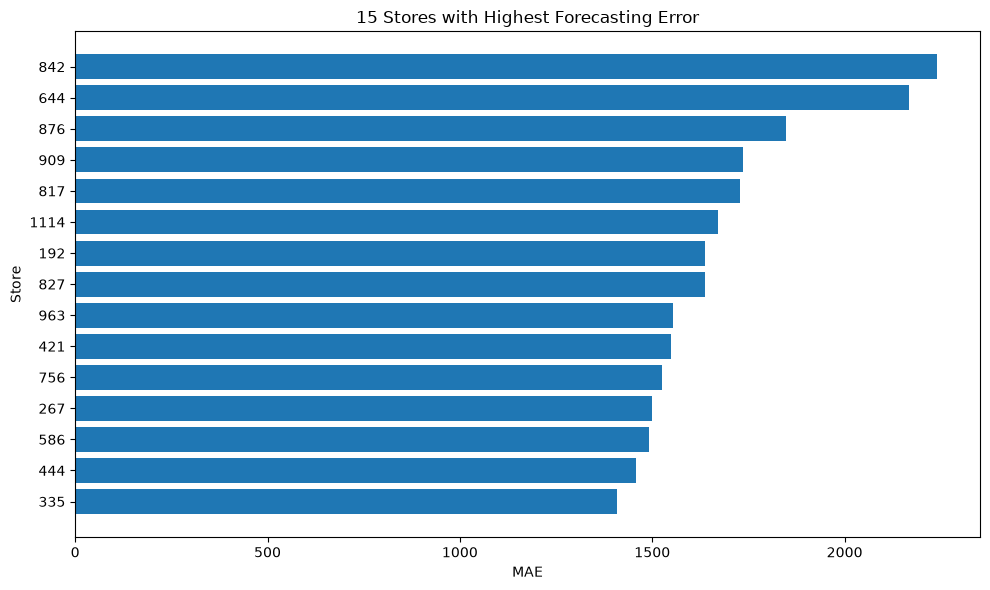

In [6]:
worst = (
    store_metrics
    .sort_values("MAE", ascending=False)
    .head(15)
    .sort_values("MAE")
)

plt.figure(figsize=(10, 6))
plt.barh(worst["Store"].astype(str), worst["MAE"])
plt.xlabel("MAE")
plt.ylabel("Store")
plt.title("15 Stores with Highest Forecasting Error")
plt.tight_layout()
plt.show()


In [7]:
features = pd.read_csv(
    "../data/processed/supervised_features.csv",
    usecols=["Store", "Date"],
    parse_dates=["Date"]
)

history = (
    features.groupby("Store")
    .agg(
        History_Days=("Date", "nunique"),
        First_Date=("Date", "min"),
        Last_Date=("Date", "max")
    )
    .reset_index()
)

history["History_Category"] = np.select(
    [
        history["History_Days"] < 30,
        history["History_Days"] < 90
    ],
    [
        "Very Sparse (<30 days)",
        "Limited (30–89 days)"
    ],
    default="Sufficient for initial analysis (90+ days)"
)

history["History_Category"].value_counts()

History_Category
Sufficient for initial analysis (90+ days)    1115
Name: count, dtype: int64

In [8]:
store_metrics.to_csv(
    "../data/processed/day12_store_metrics.csv",
    index=False
)

history.to_csv(
    "../data/processed/day12_store_history.csv",
    index=False
)

print("Store metrics and history saved successfully!")

Store metrics and history saved successfully!


# Day 12 — Global vs Store-Level Analysis

## Objective
Evaluate the global forecasting model across individual stores and inspect historical-data availability.

## Global Model
The XGBoost model was trained using data from multiple stores. Its predictions were evaluated separately for each store.

## Store-Level Evaluation
Store-level MAE and RMSE were calculated to identify differences in forecasting performance.

## Sparse Store Analysis
Stores were categorized by the amount of historical data available. Stores with limited history require additional care when selecting a forecasting strategy.

## Outputs
- day12_store_metrics.csv
- day12_store_history.csv

## Limitation
The analysis covers the available validation period. A global model does not automatically solve cold-start forecasting for stores with no historical observations.